# Лабораторная работа №3: Оптимизация гиперпараметров

**Задача:** классификация Titanic из лабораторной №2 (`Survived`), те же признаки и тот же стратифицированный split 80/20 (`random_state=42`). **Модель:** Gradient Boosting. **Метрика:** F1 класса 1.  
**Честный эксперимент:** гиперпараметры выбираются только кросс-валидацией на train; тест используется один раз, в разделе 6.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_score, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

RANDOM_STATE = 42
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## 1. Данные и baseline
Предобработка как в лабораторной №2 (медиана / мода + One-Hot; деревьям масштабирование не нужно), обучается внутри `Pipeline` только на train (на каждом фолде — только на его обучающей части).

**Baseline** — Gradient Boosting с параметрами по умолчанию. Его качество до оптимизации фиксируется по CV на train; тестовое значение показано в разделе 6.

In [2]:
if Path("Titanic-Dataset.csv").exists():
    df = pd.read_csv("Titanic-Dataset.csv")
elif Path("archive.zip").exists():
    df = pd.read_csv("archive.zip")
else:
    raise FileNotFoundError("Положите Titanic-Dataset.csv или archive.zip рядом с ноутбуком")

df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
df["Title"] = df["Title"].where(df["Title"].isin(["Mr", "Mrs", "Miss", "Master"]), "Rare")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

NUM_COLS = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
CAT_COLS = ["Pclass", "Sex", "Embarked", "Title"]
X, y = df[NUM_COLS + CAT_COLS], df["Survived"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("train:", X_train.shape, "| test:", X_test.shape, "(test до финального раздела не используется)")

def make_pipe(**params):
    """Предобработка (обучается только на train/фолде) + Gradient Boosting с заданными гиперпараметрами."""
    prep = ColumnTransformer([
        ("num", SimpleImputer(strategy="median"), NUM_COLS),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CAT_COLS)])
    return Pipeline([("prep", prep), ("model", GradientBoostingClassifier(random_state=RANDOM_STATE, **params))])

train: (712, 9) | test: (179, 9) (test до финального раздела не используется)


In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

baseline = make_pipe()
p = baseline.named_steps["model"].get_params()
print("Исходные параметры baseline:", {k: p[k] for k in ["n_estimators", "learning_rate", "max_depth", "subsample", "min_samples_leaf"]})

baseline_folds = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1")
print("F1 по фолдам:", baseline_folds.round(3))
print("Baseline: CV F1 = %.3f ± %.3f" % (baseline_folds.mean(), baseline_folds.std()))

Исходные параметры baseline: {'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 1.0, 'min_samples_leaf': 1}
F1 по фолдам: [0.796 0.705 0.796 0.705 0.755]
Baseline: CV F1 = 0.751 ± 0.041


## 2. Гиперпараметры

| Гиперпараметр | Смысл | Диапазон (Grid / Random) | Ожидаемое влияние |
|---|---|---|---|
| `learning_rate` | вклад каждого дерева в ансамбль | 0.01–0.3 / 0.005–0.5 (лог-шкала) | мал — недообучение; велик — быстрая подгонка под шум, переобучение |
| `max_depth` | глубина базовых деревьев (сложность взаимодействий) | 1–5 / 1–6 | мала — недообучение; велика — запоминание train |
| `n_estimators` | число деревьев | 50–400 / 50–500 | мало — недообучение; много — переобучение; связан с `learning_rate` |

Больше параметров не берём, чтобы не раздувать пространство поиска.

## 3. Кросс-валидация
**5-fold стратифицированная CV** на train (712 объектов): валидационный фолд ≈ 142 объекта (≈ 55 положительных), обучение на 80% данных. При 10 folds валидация вдвое меньше (≈ 27 положительных) — шумнее и вдвое дольше; при 3 folds обучение на 67% данных — оценка пессимистичнее. Стратификация сохраняет долю класса 1 (≈ 38%).

- **Зачем CV:** оценить качество на данных, не виденных при обучении, не трогая test; усреднение по k разбиениям даёт и среднее, и разброс (устойчивость).
- **Почему одного разбиения мало:** оценка зависит от того, какие объекты в него попали (на малой выборке она шумная), и параметры подгоняются под это разбиение. Если выбирать по test, он перестаёт быть независимой проверкой.
- **Если многократно выбирать параметры по test:** лучший вариант — максимум по шумным оценкам, поэтому он оптимистично смещён («эффект победителя»); информация о test «утекает» в модель, итоговая оценка завышена. Это критическая ошибка, поэтому test в подборе не участвует.

## 4. Grid Search

In [4]:
param_grid = {"model__learning_rate": [0.01, 0.03, 0.1, 0.3],
              "model__max_depth": [1, 2, 3, 5],
              "model__n_estimators": [50, 100, 200, 400]}

grid = GridSearchCV(make_pipe(), param_grid, scoring="f1", cv=cv, n_jobs=-1)
t0 = time.perf_counter(); grid.fit(X_train, y_train); grid_time = time.perf_counter() - t0

n_grid = len(grid.cv_results_["params"])
print("Пространство поиска:", {k.replace("model__", ""): v for k, v in param_grid.items()})
print(f"Проверено комбинаций: {n_grid} (обучений моделей: {n_grid * cv.get_n_splits()})")
print("Лучшие параметры:", {k.replace("model__", ""): v for k, v in grid.best_params_.items()})
print("CV F1 = %.3f ± %.3f" % (grid.best_score_, grid.cv_results_["std_test_score"][grid.best_index_]))
print("Время поиска: %.1f с" % grid_time)

Пространство поиска: {'learning_rate': [0.01, 0.03, 0.1, 0.3], 'max_depth': [1, 2, 3, 5], 'n_estimators': [50, 100, 200, 400]}
Проверено комбинаций: 64 (обучений моделей: 320)
Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 50}
CV F1 = 0.777 ± 0.036
Время поиска: 55.8 с


## 5. Random Search
Тот же бюджет — 64 комбинации (320 обучений). `learning_rate` ~ логарифмически равномерное [0.005, 0.5], `max_depth` — целое 1–6, `n_estimators` — целое 50–500.

In [5]:
param_dist = {"model__learning_rate": loguniform(0.005, 0.5),
              "model__max_depth": randint(1, 7),
              "model__n_estimators": randint(50, 501)}
rand = RandomizedSearchCV(make_pipe(), param_dist, n_iter=n_grid, scoring="f1", cv=cv,
                          n_jobs=-1, random_state=RANDOM_STATE)
t0 = time.perf_counter(); rand.fit(X_train, y_train); rand_time = time.perf_counter() - t0

n_rand = len(rand.cv_results_["params"])
print(f"Проверено комбинаций: {n_rand} (обучений моделей: {n_rand * cv.get_n_splits()})")
print("Лучшие параметры:", {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, float) else int(v)) for k, v in rand.best_params_.items()})
print("CV F1 = %.3f ± %.3f" % (rand.best_score_, rand.cv_results_["std_test_score"][rand.best_index_]))
print("Время поиска: %.1f с" % rand_time)

print("\nЧисло различных значений, проверенных для learning_rate: grid =",
      pd.Series([p["model__learning_rate"] for p in grid.cv_results_["params"]]).nunique(),
      "| random =", pd.Series([p["model__learning_rate"] for p in rand.cv_results_["params"]]).nunique())

pd.DataFrame({
    "Комбинаций": [n_grid, n_rand],
    "Лучший CV F1": [grid.best_score_, rand.best_score_],
    "Время, с": [grid_time, rand_time]}, index=["Grid Search", "Random Search"]).round(3)

Проверено комбинаций: 64 (обучений моделей: 320)
Лучшие параметры: {'learning_rate': 0.0196, 'max_depth': 5, 'n_estimators': 114}
CV F1 = 0.770 ± 0.031
Время поиска: 92.2 с

Число различных значений, проверенных для learning_rate: grid = 4 | random = 64


,Комбинаций,Лучший CV F1,"Время, с"
Grid Search,64,0.777,55.811
Random Search,64,0.770,92.187


**Сравнение с Grid Search**
- **Качество:** CV F1 практически равно (0.777 и 0.770); разница меньше разброса по фолдам (std ≈ 0.03–0.04).
- **Комбинации:** 64 и 64, но Random проверил 64 разных значения `learning_rate`, Grid — 4.
- **Время:** Random дольше (≈ 90 с против ≈ 55 с): он выбирал в среднем более «дорогие» модели (до 500 деревьев, глубина до 6), а равное число комбинаций не означает равного времени. Абсолютные значения зависят от машины.

**Когда Random Search предпочтительнее:** много гиперпараметров, из которых важны лишь некоторые (при том же бюджете проверяется больше различных значений важных параметров); непрерывные параметры и широкие диапазоны; размер сетки растёт экспоненциально, а число проб задаётся напрямую. Grid Search лучше при 1–2 параметрах и малом дискретном пространстве.

### Влияние гиперпараметров
Зависимость F1 от одного параметра при остальных, зафиксированных на лучших значениях Grid Search (только train, полосы — ±1 std по фолдам). Серая линия — значение лучшей модели Grid Search.

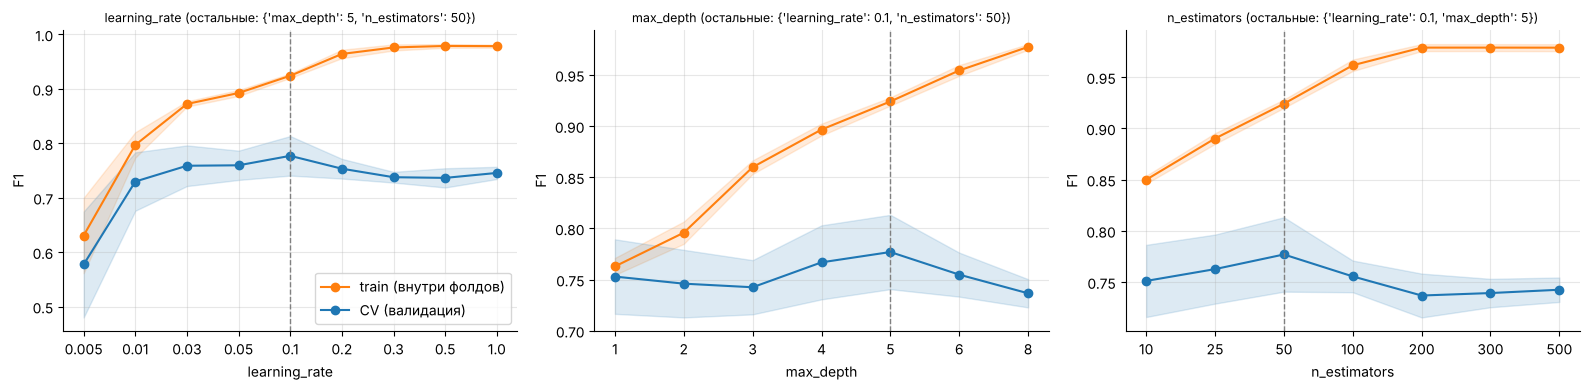

In [6]:
best = {k.replace("model__", ""): v for k, v in grid.best_params_.items()}
ranges = {"learning_rate": [0.005, 0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0],
          "max_depth": [1, 2, 3, 4, 5, 6, 8],
          "n_estimators": [10, 25, 50, 100, 200, 300, 500]}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, values) in zip(axes, ranges.items()):
    fixed = {k: v for k, v in best.items() if k != name}
    tr, va = validation_curve(make_pipe(**fixed), X_train, y_train, param_name=f"model__{name}",
                              param_range=values, cv=cv, scoring="f1", n_jobs=-1)
    for sc, lbl, c in [(tr, "train (внутри фолдов)", "tab:orange"), (va, "CV (валидация)", "tab:blue")]:
        ax.plot(range(len(values)), sc.mean(axis=1), "o-", label=lbl, color=c)
        ax.fill_between(range(len(values)), sc.mean(axis=1) - sc.std(axis=1), sc.mean(axis=1) + sc.std(axis=1), alpha=0.15, color=c)
    ax.set_xticks(range(len(values))); ax.set_xticklabels(values)
    ax.axvline(values.index(best[name]) if best[name] in values else 0, color="gray", ls="--", lw=1)
    ax.set(title=f"{name} (остальные: {fixed})", xlabel=name, ylabel="F1"); ax.title.set_fontsize(9)
axes[0].legend(); plt.tight_layout(); plt.show()

| Параметр | Недообучение | Разумная сложность | Переобучение |
|---|---|---|---|
| `learning_rate` | ≤ 0.005: train ≈ 0.63, CV ≈ 0.58 | 0.01–0.1: максимум CV ≈ 0.78 при 0.1 | ≥ 0.2: train → 0.98, CV ≈ 0.74 |
| `max_depth` | 1–3: train ≈ CV, обе невысокие | 4–5: максимум CV ≈ 0.78 | ≥ 6: train → 0.98, CV ≈ 0.74 |
| `n_estimators` | ≈ 10: train ≈ 0.85, CV ≈ 0.75 | ≈ 50: максимум CV ≈ 0.78 | ≥ 100: train → 0.98, CV ≈ 0.74 |

**Объяснение.** Все три параметра повышают сложность ансамбля: train F1 растёт монотонно, а CV F1 — до некоторой точки, после чего падает: модель запоминает шум, разрыв train–CV растёт. Параметры связаны: при `learning_rate = 0.1` и глубине 5 хватает 50 деревьев. Вблизи максимума CV-кривые плоские и лежат внутри полос ±std (различия ≈ 0.01–0.03 сопоставимы с шумом), уверенно различимы лишь крайние области.

## 6. Финальная модель
Лучшие модели поисков переобучены на всём train (`refit=True`). **Только теперь** baseline, лучшая Grid Search и лучшая Random Search оцениваются на тесте.

In [7]:
baseline.fit(X_train, y_train)
models = {"Baseline (по умолчанию)": baseline,
          "Grid Search": grid.best_estimator_,
          "Random Search": rand.best_estimator_}
cv_mean = {"Baseline (по умолчанию)": baseline_folds.mean(), "Grid Search": grid.best_score_, "Random Search": rand.best_score_}
cv_std = {"Baseline (по умолчанию)": baseline_folds.std(),
          "Grid Search": grid.cv_results_["std_test_score"][grid.best_index_],
          "Random Search": rand.cv_results_["std_test_score"][rand.best_index_]}

final = pd.DataFrame({
    "CV F1 (mean)": cv_mean, "CV F1 (std)": cv_std,
    "Test F1": {n: f1_score(y_test, m.predict(X_test)) for n, m in models.items()},
    "Test Accuracy": {n: accuracy_score(y_test, m.predict(X_test)) for n, m in models.items()}})
final["Δ CV F1 к baseline"] = final["CV F1 (mean)"] - final.loc["Baseline (по умолчанию)", "CV F1 (mean)"]
final["Δ Test F1 к baseline"] = final["Test F1"] - final.loc["Baseline (по умолчанию)", "Test F1"]
final.round(3)

,CV F1 (mean),CV F1 (std),Test F1,Test Accuracy,Δ CV F1 к baseline,Δ Test F1 к baseline
Baseline (по умолчанию),0.751,0.041,0.740,0.816,0.000,0.000
Grid Search,0.777,0.036,0.744,0.816,0.026,0.004
Random Search,0.770,0.031,0.760,0.827,0.019,0.020


- **Улучшение:** на CV +0.026 (Grid) и +0.019 (Random); на тесте +0.004 и +0.020. Оно небольшое: данные шумные, baseline уже близок к потолку.
- **Совпадает ли CV с test:** не полностью. На CV лучше Grid (0.777 против 0.770), на тесте — Random (0.760 против 0.744); выигрыш Grid на CV почти не подтвердился на тесте. У всех моделей test F1 ниже CV F1.
- **Причины:** (1) тест мал (179 объектов, 69 положительных), а F1 по фолдам различается на ≈ 0.09, так что разницы 0.004–0.02 лежат в пределах шума; (2) лучшая из 64 конфигураций по CV — максимум по шумным оценкам, её CV-оценка слегка оптимистична, а топ-10 конфигураций Grid отличаются всего на ≈ 0.016 (меньше std по фолдам); (3) тест — единственная реализация одного разбиения.

## 7. Анализ устойчивости
F1 по отдельным фолдам для лучших параметров каждой модели.

,Baseline (по умолчанию),Grid Search,Random Search
fold 1,0.796,0.807,0.814
fold 2,0.705,0.738,0.745
fold 3,0.796,0.832,0.800
fold 4,0.705,0.748,0.736
fold 5,0.755,0.760,0.755


,mean,std,min,max,размах
Baseline (по умолчанию),0.751,0.041,0.705,0.796,0.092
Grid Search,0.777,0.036,0.738,0.832,0.094
Random Search,0.770,0.031,0.736,0.814,0.078


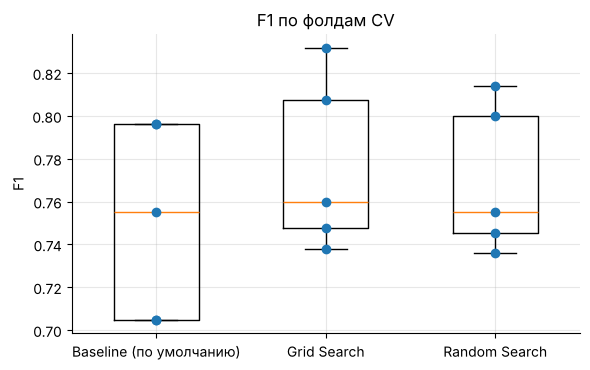

,params,mean_test_score,std_test_score
0,"{'learning_rate': 0.1, 'max_depth': 5, 'n_esti...",0.777,0.036
1,"{'learning_rate': 0.03, 'max_depth': 5, 'n_est...",0.773,0.034
2,"{'learning_rate': 0.3, 'max_depth': 1, 'n_esti...",0.771,0.035
3,"{'learning_rate': 0.01, 'max_depth': 5, 'n_est...",0.770,0.035
4,"{'learning_rate': 0.03, 'max_depth': 5, 'n_est...",0.769,0.014
5,"{'learning_rate': 0.01, 'max_depth': 5, 'n_est...",0.767,0.024
6,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.763,0.036
7,"{'learning_rate': 0.1, 'max_depth': 1, 'n_esti...",0.762,0.034
8,"{'learning_rate': 0.3, 'max_depth': 1, 'n_esti...",0.762,0.039
9,"{'learning_rate': 0.03, 'max_depth': 1, 'n_est...",0.761,0.044


In [8]:
def folds_at(search):
    i = search.best_index_
    return np.array([search.cv_results_[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())])

folds = pd.DataFrame({"Baseline (по умолчанию)": baseline_folds, "Grid Search": folds_at(grid), "Random Search": folds_at(rand)},
                     index=[f"fold {k + 1}" for k in range(cv.get_n_splits())])
summary = pd.DataFrame({"mean": folds.mean(), "std": folds.std(ddof=0), "min": folds.min(), "max": folds.max()})
summary["размах"] = summary["max"] - summary["min"]
display(folds.round(3)); display(summary.round(3))

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.boxplot(folds.values, widths=0.5); ax.set_xticklabels(folds.columns)
for i, c in enumerate(folds.columns, 1):
    ax.scatter(np.full(len(folds), i), folds[c], color="tab:blue", zorder=3)
ax.set(title="F1 по фолдам CV", ylabel="F1"); plt.tight_layout(); plt.show()

r = pd.DataFrame(grid.cv_results_)
top = r.sort_values("mean_test_score", ascending=False).head(10)[["params", "mean_test_score", "std_test_score"]]
top["params"] = top["params"].apply(lambda d: {k.replace("model__", ""): v for k, v in d.items()})
top.round(3).reset_index(drop=True)

- Среднее растёт (0.751 → 0.777 / 0.770), а разброс почти не меняется: std ≈ 0.04 / 0.036 / 0.031, размах ≈ 0.08–0.09. Random немного устойчивее, но различие в std мало.
- У всех трёх моделей слабее всего фолды 2 и 4, сильнее — 1 и 3: основной разброс определяется «трудностью» валидационных подвыборок, поэтому модели сравниваются на одних и тех же фолдах и с учётом std.
- Среди топ-10 конфигураций Grid есть варианты с почти одинаковым средним (≈ 0.77), но std от ≈ 0.014 до ≈ 0.036.

**Почему при равном среднем устойчивость различается:** среднее скрывает распределение по фолдам — одна модель стабильно даёт ≈ 0.77, другая колеблется от 0.72 до 0.83. Более сложная модель (глубокие деревья, много деревьев, большой шаг) сильнее зависит от состава обучающей выборки, то есть имеет большую дисперсию. При равном среднем предпочтительна модель с меньшим std.

## 8. Итоги
1. Baseline (параметры по умолчанию): CV F1 = 0.751, Test F1 = 0.740.
2. Grid Search (64 комбинации): CV F1 = 0.777, Test F1 = 0.744. Random Search (64 комбинации): CV F1 = 0.770, Test F1 = 0.760.
3. Области: недообучение — малые `learning_rate`, `max_depth`, `n_estimators`; разумная сложность — `learning_rate` ≈ 0.1, `max_depth` 4–5, `n_estimators` ≈ 50; переобучение — большие значения.
4. Улучшение умеренное и на CV и на test не совпадает (малый тест, шум, смещение выбора лучшей конфигурации); разброс по фолдам (std ≈ 0.03–0.04) сопоставим с выигрышем от оптимизации.

*Числа соответствуют запуску с `random_state=42`; время зависит от машины, при другой версии scikit-learn возможны небольшие отличия.*